In [32]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [33]:
class AgentState(TypedDict):
    number1: int
    operation1: str
    number2: int
    number3: int
    operation2: str
    number4: int
    finalNumber1: int
    finalNumber2: int

In [34]:
def add_node_1(state: AgentState) -> AgentState:
    state["finalNumber1"] = state["number1"] + state["number2"]
    return state

def subtract_node_1(state: AgentState) -> AgentState:
    state["finalNumber2"] = state["number3"] - state["number4"]
    return state

def add_node_2(state: AgentState) -> AgentState:
    state["finalNumber2"] = state["number3"] + state["number4"]
    return state


def subtract_node_2(state: AgentState) -> AgentState:
    state["finalNumber2"] = state["number3"] - state["number4"]
    return state

# Router 1
def decide_next_node_1(state: AgentState):
    if state["operation1"] == "+":
        return "addition_operation_1"
    elif state["operation1"] == "-":
        return "subtraction_operation_1"
    else:
        raise ValueError("Invalid operation 1")


# Router 2
def decide_next_node_2(state: AgentState):
    if state["operation2"] == "+":
        return "addition_operation_2"
    elif state["operation2"] == "-":
        return "subtraction_operation_2"
    else:
        raise ValueError("Invalid operation 2")


In [35]:
graph = StateGraph(AgentState)

graph.add_node("adder1", add_node_1)
graph.add_node("subtracter1", subtract_node_1)
graph.add_node("router1", lambda state: state)  # Router1 just passes the state through
graph.add_node("adder2", add_node_2)
graph.add_node("subtracter2", subtract_node_2)
graph.add_node("router2", lambda state: state)  # Router2 just passes the state through

graph.add_edge(START, "router1")
graph.add_conditional_edges(
    "router1",
    decide_next_node_1,
    {
        "addition_operation_1": "adder1",
        "subtraction_operation_1": "subtracter1"
    }
)
graph.add_edge("adder1", "router2")
graph.add_edge("subtracter1", "router2")
graph.add_conditional_edges(
    "router2",
    decide_next_node_2,
    {
        "addition_operation_2": "adder2",
        "subtraction_operation_2": "subtracter2"
    }
)

graph.add_edge("adder2", END)
graph.add_edge("subtracter2", END)

compiler = graph.compile()

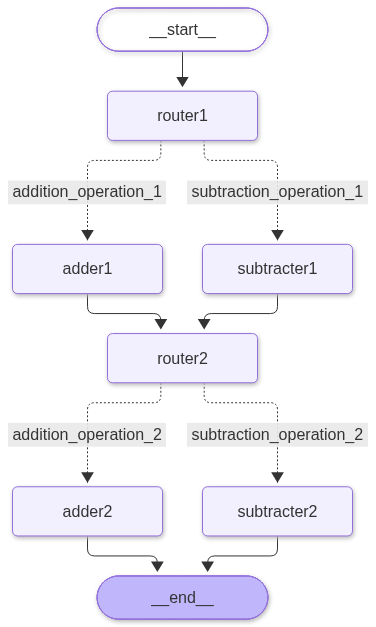

In [36]:
from IPython.display import display, Image
display(Image(compiler.get_graph().draw_mermaid_png()))

In [37]:
initial_state = AgentState(
    number1=10,
    operation1="+",
    number2=5,
    number3=20,
    operation2="-",
    number4=8,
)

print(compiler.invoke(initial_state)["finalNumber1"]) 
print(compiler.invoke(initial_state)["finalNumber2"])  

15
12
